# code_138 · Generative contracts, conditional completion and linked records

**Book:** section 27.1. A self-contained generative-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_27_GUIDE.md), [run evidence](../CHAPTER_27_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_138).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3338;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3338


<a id="generation-contract"></a>
 ## Joint generation, conditioning and completion ask different questions
 Sixty generated buildings each supply twenty correlated records. Source40/development10/final10 buildings remain whole groups. An observed operating regime c selects a two-mode joint distribution of log load and log stiffness, with a shared building effect. Physical load/stiffness are positive exponentials and a declared scalar toy response is their ratio. Compare independent marginals, a joint Gaussian mixture ignoring regime dependence, and regime-conditional mixtures. Candidate component counts1/2/4 select on development log density; no final selection occurs. Generate2,000 candidate records and separately complete withheld log stiffness conditional on admitted load and regime. Fresh linked parent/member/inspection tables illustrate keys/time constraints; these structural rules are explicit generation code rather than learned database semantics. No reference cohort is field data.


,generator,final_conditional_log_density,log_field_correlation,regime_load_log_mean_difference,response_mean,response_q95,generated_records
0,Independent fields,-1.632000,-0.001062,0.043964,4.304317,11.402393,2000
1,Joint mixture,-1.198627,0.756867,-0.097024,3.630074,6.204926,2000
2,Conditional mixture,-1.162551,0.763826,0.292573,3.538665,6.136729,2000


Completion and relational checks: 0.1525850635984643 0.24685642382189443 {'orphan_members': 0, 'orphan_inspections': 0, 'reports_before_events': 0} {'orphan_members': 0, 'orphan_inspections': 18, 'reports_before_events': 41}


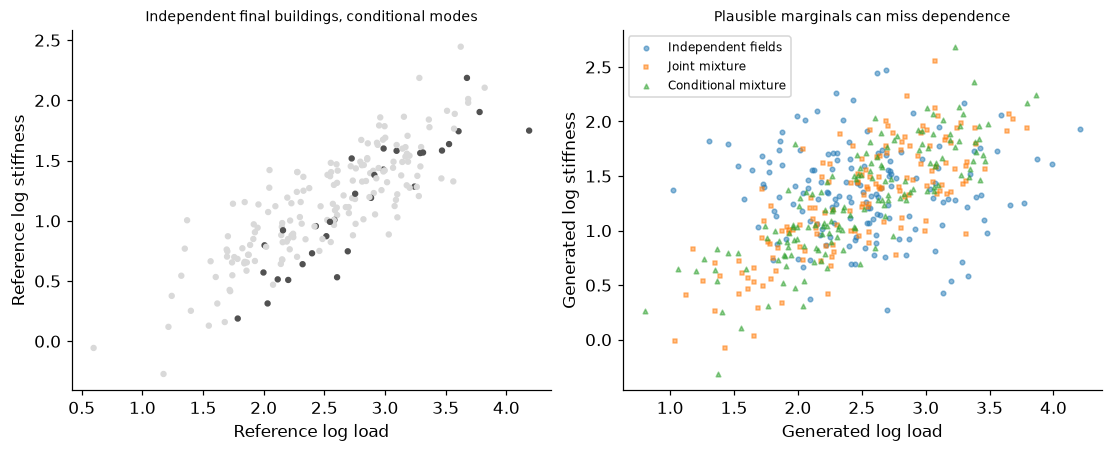

In [2]:
from sklearn.mixture import GaussianMixture
from scipy.special import logsumexp
from scipy.stats import norm
B,R=60,20;building=np.repeat(np.arange(B),R);regime=rng.binomial(1,.2,B*R);mode=rng.binomial(1,np.where(regime==1,.3,.6));offset=rng.normal(0,.15,(B,2));cov=np.array([[.16,.10],[.10,.12]]);z=np.column_stack([2+.5*regime+.8*mode,1+.2*regime+.5*mode])+offset[building]+rng.multivariate_normal(np.zeros(2),cov,B*R);train=building<40;dev=(building>=40)&(building<50);final=building>=50;prior=float(regime[train].mean());candidates=[]
def fit_mixture(source,validation,label):
    choices=[]
    for k in [1,2,4]:
        m=GaussianMixture(k,covariance_type='full',reg_covar=1e-5,n_init=2,random_state=SEED,max_iter=300).fit(source);assert m.converged_;score=float(m.score(validation));choices.append((score,k,m));candidates.append({'scope':label,'components':k,'development_mean_log_density':score})
    return max(choices,key=lambda a:a[0])[2]
joint=fit_mixture(z[train],z[dev],'Joint');conditional={c:fit_mixture(z[train&(regime==c)],z[dev&(regime==c)],f'Condition {c}') for c in [0,1]};mean=z[train].mean(0);sd=z[train].std(0)
def draw(model,n):
    choices=rng.choice(model.n_components,n,p=model.weights_);result=np.empty((n,2))
    for k in range(model.n_components):indices=np.flatnonzero(choices==k);result[indices]=rng.multivariate_normal(model.means_[k],model.covariances_[k],len(indices))
    return result
generated={};N=2000
for name in ['Independent fields','Joint mixture','Conditional mixture']:
    c=rng.binomial(1,prior,N)
    if name=='Independent fields':sample=mean+rng.normal(size=(N,2))*sd
    elif name=='Joint mixture':sample=draw(joint,N)
    else:
        sample=np.empty((N,2))
        for value in [0,1]:indices=np.flatnonzero(c==value);sample[indices]=draw(conditional[value],len(indices))
    generated[name]=(sample,c)
rows=[];true_z=z[final];true_c=regime[final]
for name,(sample,c) in generated.items():
    logdensity=np.sum(norm.logpdf(true_z,mean,sd),axis=1) if name=='Independent fields' else joint.score_samples(true_z) if name=='Joint mixture' else np.array([conditional[int(c0)].score_samples(row[None,:])[0] for row,c0 in zip(true_z,true_c)])
    load=np.exp(sample[:,0]);stiffness=np.exp(sample[:,1]);response=load/stiffness;assert np.all(load>0)&np.all(stiffness>0)&np.all(response>0)
    rows.append({'generator':name,'final_conditional_log_density':float(logdensity.mean()),'log_field_correlation':float(np.corrcoef(sample.T)[0,1]),'regime_load_log_mean_difference':float(sample[c==1,0].mean()-sample[c==0,0].mean()),'response_mean':float(response.mean()),'response_q95':float(np.quantile(response,.95)),'generated_records':N})
# Conditional distribution of missing second coordinate, given first coordinate and declared regime.
def complete(first,c,n_draws=100):
    model=conditional[int(c)];means=model.means_;covs=model.covariances_;logweights=np.log(model.weights_)+norm.logpdf(first,means[:,0],np.sqrt(covs[:,0,0]));weights=np.exp(logweights-logsumexp(logweights));means1=means[:,1]+covs[:,1,0]/covs[:,0,0]*(first-means[:,0]);variances=covs[:,1,1]-covs[:,1,0]**2/covs[:,0,0];components=rng.choice(model.n_components,n_draws,p=weights);samples=np.column_stack([np.full(n_draws,first),means1[components]+rng.normal(size=n_draws)*np.sqrt(variances[components])]);return samples,float(weights@means1)
completed=[]
for observed,c in zip(true_z[:50],true_c[:50]):
    samples,conditional_mean=complete(observed[0],c);np.testing.assert_array_equal(samples[:,0],np.full(100,observed[0]));completed.append(conditional_mean)
imputation_MSE=float(np.mean((np.array(completed)-true_z[:50,1])**2));unconditional_MSE=float(np.mean((mean[1]-true_z[:50,1])**2))
parents=pd.DataFrame({'building_id':np.arange(20)});members=[];inspections=[]
for parent in parents.building_id:
    for j in range(int(rng.poisson(3)+1)):
        member_id=len(members);members.append({'member_id':member_id,'building_id':int(parent)});event=float(rng.uniform(1,20));inspections.append({'inspection_id':len(inspections),'member_id':member_id,'event_time':event,'report_time':event+float(rng.exponential(2))})
members=pd.DataFrame(members);inspections=pd.DataFrame(inspections)
def audit(member_table,inspection_table):return {'orphan_members':int((~member_table.building_id.isin(parents.building_id)).sum()),'orphan_inspections':int((~inspection_table.member_id.isin(member_table.member_id)).sum()),'reports_before_events':int((inspection_table.report_time<inspection_table.event_time).sum())}
valid=audit(members,inspections);bad=inspections.copy();bad.member_id=rng.integers(0,len(members)+20,len(bad));bad.report_time=bad.event_time+rng.normal(0,2,len(bad));invalid=audit(members,bad);assert sum(valid.values())==0 and sum(invalid.values())>0
RESULTS.update(comparisons=rows,mixture_candidates=candidates,selected_joint_components=joint.n_components,selected_conditional_components={str(c):m.n_components for c,m in conditional.items()},building_counts=[40,10,10],record_counts=[int(train.sum()),int(dev.sum()),int(final.sum())],source_regime_prevalence=prior,final_log_field_correlation=float(np.corrcoef(true_z.T)[0,1]),final_regime_load_log_mean_difference=float(true_z[true_c==1,0].mean()-true_z[true_c==0,0].mean()),conditional_completion_MSE=imputation_MSE,unconditional_completion_MSE=unconditional_MSE,linked_table_counts=[len(parents),len(members),len(inspections)],valid_table_audit=valid,independent_table_audit=invalid);display(pd.DataFrame(rows));print('Completion and relational checks:',imputation_MSE,unconditional_MSE,valid,invalid)
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].scatter(true_z[:,0],true_z[:,1],s=10,c=true_c,cmap='Greys',vmin=-.5,vmax=1.5);axes[0].set(xlabel='Reference log load',ylabel='Reference log stiffness',title='Independent final buildings, conditional modes')
for name,style in zip(generated,['o','s','^']):sample,c=generated[name];axes[1].scatter(sample[:150,0],sample[:150,1],s=9,marker=style,alpha=.5,label=name)
axes[1].set(xlabel='Generated log load',ylabel='Generated log stiffness',title='Plausible marginals can miss dependence');axes[1].legend(fontsize=8);plt.show()


<a id="completion-relations-and-use"></a>
 ## A valid record is not automatically a useful dataset
 Conditional completion preserves the admitted first coordinate exactly and samples the missing coordinate; averaging draws is a separate point-imputation choice. Conditioning on an operating regime is a declared scenario request, not evidence that a future regime label is available in a forecasting task. Derived positive physical fields follow explicit scalar rules rather than a learned beam law. Linked-table validation checks foreign keys and report/event order independently of continuous density scores. The deliberately invalid table sampler is kept as an audit fixture. Entity counts remain visible because records from the same building share a generating offset; no independent-row confidence claim is made. Downstream utility and disclosure checks need separate experiments.


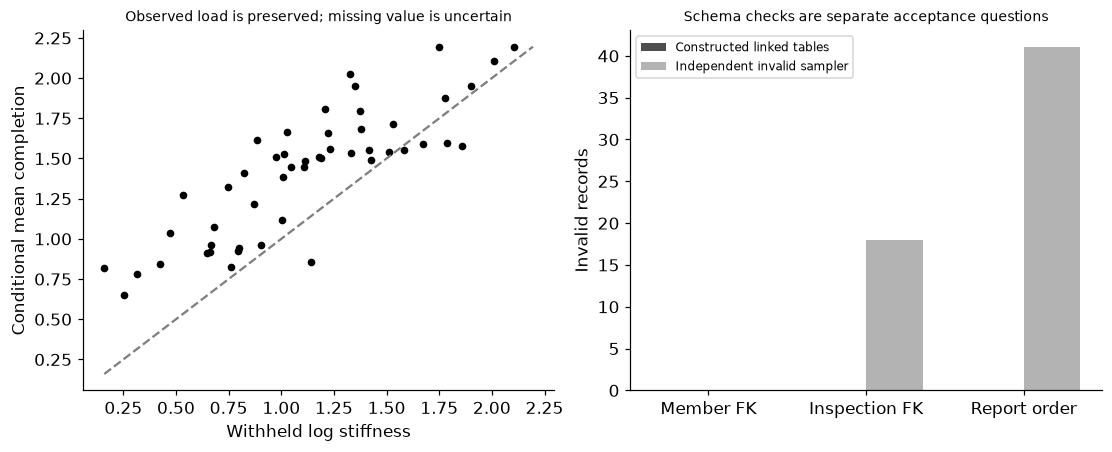

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].scatter(true_z[:50,1],completed,color='black',s=16);lo=min(true_z[:50,1].min(),min(completed));hi=max(true_z[:50,1].max(),max(completed));axes[0].plot([lo,hi],[lo,hi],'--',color='.5');axes[0].set(xlabel='Withheld log stiffness',ylabel='Conditional mean completion',title='Observed load is preserved; missing value is uncertain');labels=list(valid);xx=np.arange(len(labels));axes[1].bar(xx-.18,list(valid.values()),.36,color='.3',label='Constructed linked tables');axes[1].bar(xx+.18,list(invalid.values()),.36,color='.7',label='Independent invalid sampler');axes[1].set(xticks=xx,xticklabels=['Member FK','Inspection FK','Report order'],ylabel='Invalid records',title='Schema checks are separate acceptance questions');axes[1].legend(fontsize=8);plt.show()
assert all(np.isfinite(r['final_conditional_log_density']) for r in rows)


In [4]:
summary={'example_id':'code_138','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual joint and conditional mixture sampling', 'independent-marginal reference', 'conditional Gaussian-mixture imputation', 'generated relational keys and temporal constraints', 'whole-building evidence boundaries'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual joint and conditional mixture sampling", "independent-marginal reference", "conditional Gaussian-mixture imputation", "generated relational keys and temporal constraints", "whole-building evidence boundaries"], "elapsed_seconds": 1.54, "example_id": "code_138", "hardware": "Darwin arm64 CPU", "results": {"building_counts": [40, 10, 10], "comparisons": [{"final_conditional_log_density": -1.631999521232751, "generated_records": 2000, "generator": "Independent fields", "log_field_correlation": -0.0010620053503199234, "regime_load_log_mean_difference": 0.04396399795452899, "response_mean": 4.304316737439849, "response_q95": 11.402392970130693}, {"final_conditional_log_density": -1.1986267781504398, "generated_records": 2000, "generator": "Joint mixture", "log_field_correlation": 0.7568673718989509, "regime_load_log_mean_difference": -0.09702442580812853, "response_mean": 3.6300735225837863, "response_q95": 6.204926113610462}, {"fina